# Deep Reinforcement Learning for Battery Energy Storage Control

**Contact:** Buxin She ([shebuxin@gmail.com](mailto:shebuxin@gmail.com))  

This notebook introduces **Deep Reinforcement Learning (DRL)** through a small power-system control example. A battery energy storage system learns when to charge, discharge, or stay idle under a synthetic daily load profile and an illustrative time-varying electricity price.

The load and price arrays are teaching inputs: they are not measured field data and the price curve is not an official tariff. The goal is to help beginners connect the core DRL ideas - **state, action, reward, policy, and value function** - to a familiar power-system operation problem.

## Table of Contents

0. [Setup](#step-0-setup)
1. [Problem Statement](#step-1-problem-statement)
2. [Reinforcement Learning Formulation](#step-2-reinforcement-learning-formulation)
3. [Create Synthetic Power System Data](#step-3-create-synthetic-power-system-data)
4. [Build the Battery Environment](#step-4-build-the-battery-environment)
5. [Define the DQN Agent](#step-5-define-the-dqn-agent)
6. [Train the DQN](#step-6-train-the-dqn)
7. [Test the Learned Policy](#step-7-test-the-learned-policy)
8. [Visualize Results](#step-8-visualize-results)
9. [Further Reading](#further-reading)


## Step 0. Setup

We use NumPy for data generation, PyTorch for the DQN model, and Matplotlib for visualization. The example is intentionally small so it can run on a laptop CPU or in Google Colab.


In [48]:
# Step 0. Setup
import random
from collections import deque, namedtuple

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Keep the example CPU-friendly and deterministic enough for a demo.
device = torch.device("cpu")

# Training controls. Increase EPISODES if you want smoother learning curves.
EPISODES = 300
BATCH_SIZE = 64
GAMMA = 0.95
LEARNING_RATE = 1e-3
EPS_START = 1.00
EPS_END = 0.05
EPS_DECAY = 0.985
TARGET_UPDATE = 20

print("Setup complete. PyTorch version:", torch.__version__)
print("Using device:", device)


Setup complete. PyTorch version: 2.12.1
Using device: cpu


## Step 1. Problem Statement

Consider a small power system with:

- one fixed daily load curve;
- one electricity price curve;
- one battery energy storage system.

At each hour, the battery controller chooses one action:

- **discharge** the battery;
- **idle**;
- **charge** the battery.

The controller should reduce operating cost by charging when energy is cheap and discharging when energy is expensive, while keeping the battery state of charge (SOC) within physical limits.


In [49]:
# Discrete action space used by the reinforcement-learning agent.
# Positive command means charging from the grid; negative command means discharging to serve the load.
ACTIONS = {
    0: {"name": "discharge", "command": -1},
    1: {"name": "idle", "command": 0},
    2: {"name": "charge", "command": 1},
}

for action_id, action_info in ACTIONS.items():
    print(f"Action {action_id}: {action_info['name']}")


Action 0: discharge
Action 1: idle
Action 2: charge


## Step 2. Reinforcement Learning Formulation

We formulate the battery-control problem as a reinforcement-learning task:

| RL concept | Meaning in this notebook |
|---|---|
| Agent | Battery controller |
| Environment | Load, price, and battery SOC dynamics |
| State | `[time, price, load, SOC]` |
| Action | `{discharge, idle, charge}` |
| Reward | Scaled negative operating cost, with small penalties for cycling and invalid actions |
| Policy | Rule used by the agent to choose actions |

The DQN agent tries actions, observes rewards, and gradually learns which action has the best long-term value in each state.


In [50]:
rl_formulation = {
    "state": "[hour, electricity price, load, battery SOC]",
    "action": "discharge, idle, or charge",
    "reward": "scaled negative cost minus small battery-use and invalid-action penalties",
    "episode": "one 24-hour operating day",
    "objective": "learn a low-cost battery-control policy",
}

for key, value in rl_formulation.items():
    print(f"{key:>9}: {value}")

    state: [hour, electricity price, load, battery SOC]
   action: discharge, idle, or charge
   reward: scaled negative cost minus small battery-use and invalid-action penalties
  episode: one 24-hour operating day
objective: learn a low-cost battery-control policy


## Step 3. Create Synthetic Power System Data

We create a simple 24-hour load profile and a time-of-use electricity price profile. These arrays are synthetic teaching data, not measured field data, and the price curve is not an official tariff. We can later replace these arrays with real load and price data.


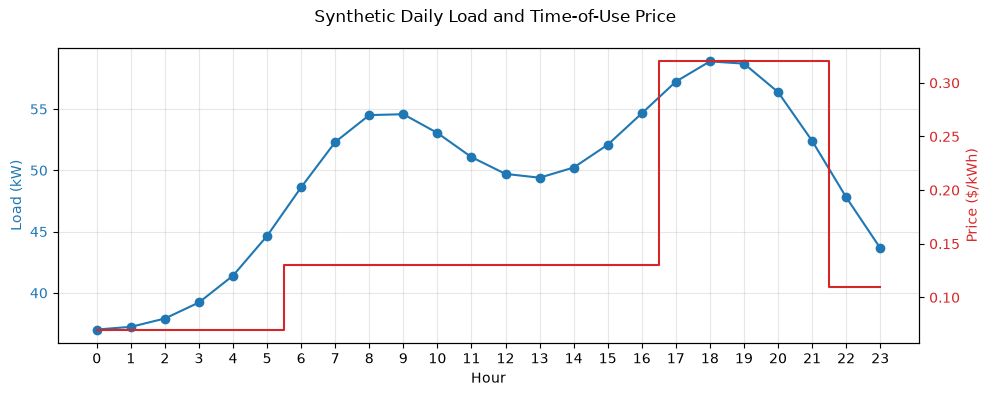

In [51]:
# Step 3. Synthetic one-day load and price data
HOURS = np.arange(24)

morning_peak = 10 * np.exp(-0.5 * ((HOURS - 8) / 2.2) ** 2)
evening_peak = 18 * np.exp(-0.5 * ((HOURS - 19) / 2.8) ** 2)
daily_shape = 42 + 5 * np.sin(2 * np.pi * (HOURS - 6) / 24)
load_kw = np.round(daily_shape + morning_peak + evening_peak, 2)

price_per_kwh = np.full(24, 0.14)
price_per_kwh[(HOURS >= 0) & (HOURS <= 5)] = 0.07
price_per_kwh[(HOURS >= 6) & (HOURS <= 16)] = 0.13
price_per_kwh[(HOURS >= 17) & (HOURS <= 21)] = 0.32
price_per_kwh[(HOURS >= 22) & (HOURS <= 23)] = 0.11

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(HOURS, load_kw, marker="o", label="Load (kW)", color="tab:blue")
ax1.set_xlabel("Hour")
ax1.set_ylabel("Load (kW)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.set_xticks(HOURS)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.step(HOURS, price_per_kwh, where="mid", label="Price ($/kWh)", color="tab:red")
ax2.set_ylabel("Price ($/kWh)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

fig.suptitle("Synthetic Daily Load and Time-of-Use Price")
fig.tight_layout()
plt.show()


## Step 4. Build the Battery Environment

The environment is a small simulator. It receives an action, updates battery SOC, computes grid power, and returns the next state and reward.

Important simplifications:

- the time step is one hour;
- the battery cannot export power back to the grid;
- charging and discharging are clipped to respect SOC limits;
- a terminal SOC penalty discourages the agent from ending far away from its initial SOC. In this default example, the battery starts empty, so the agent must learn to charge before it can discharge.


In [52]:
class BatteryStorageEnv:
    """Small battery energy-storage environment for a one-day DRL demo."""

    def __init__(
        self,
        load_kw,
        price_per_kwh,
        capacity_kwh=60.0,
        max_power_kw=15.0,
        efficiency=0.95,
        initial_soc_fraction=0.00,
        terminal_soc_penalty=0.20,
        cycling_cost=0.005,
        reward_scale=0.10,
        invalid_action_penalty=1.00,
    ):
        self.load_kw = np.asarray(load_kw, dtype=np.float32)
        self.price_per_kwh = np.asarray(price_per_kwh, dtype=np.float32)
        self.n_steps = len(self.load_kw)
        self.capacity_kwh = float(capacity_kwh)
        self.max_power_kw = float(max_power_kw)
        self.efficiency = float(efficiency)
        self.initial_soc_kwh = float(initial_soc_fraction * capacity_kwh)
        self.terminal_soc_penalty = float(terminal_soc_penalty)
        self.cycling_cost = float(cycling_cost)
        self.reward_scale = float(reward_scale)
        self.invalid_action_penalty = float(invalid_action_penalty)
        self.dt_hours = 1.0

        # Save min/max values so price and load can be scaled into a neural-network-friendly range.
        self.price_min = float(self.price_per_kwh.min())
        self.price_max = float(self.price_per_kwh.max())
        self.load_min = float(self.load_kw.min())
        self.load_max = float(self.load_kw.max())
        self.reset()

    def reset(self):
        self.t = 0
        self.soc_kwh = self.initial_soc_kwh
        self.history = []
        return self._get_state()

    def _normalize(self, value, min_value, max_value):
        return (value - min_value) / (max_value - min_value + 1e-8)

    def _get_state(self):
        # The agent observes normalized time, price, load, and SOC instead of raw engineering units.
        hour_norm = self.t / max(self.n_steps - 1, 1)
        price_norm = self._normalize(self.price_per_kwh[self.t], self.price_min, self.price_max)
        load_norm = self._normalize(self.load_kw[self.t], self.load_min, self.load_max)
        soc_norm = self.soc_kwh / self.capacity_kwh
        return np.array([hour_norm, price_norm, load_norm, soc_norm], dtype=np.float32)

    def step(self, action):
        # One environment step applies the action, updates SOC, computes cost, and returns feedback.
        action_info = ACTIONS[int(action)]
        command = action_info["command"]

        load = float(self.load_kw[self.t])
        price = float(self.price_per_kwh[self.t])
        invalid_action = 0.0
        battery_power_kw = 0.0

        if command > 0:  # charge from grid
            max_grid_charge_kw = min(
                self.max_power_kw,
                (self.capacity_kwh - self.soc_kwh) / (self.efficiency * self.dt_hours),
            )
            charge_kw = max(0.0, max_grid_charge_kw)
            if charge_kw < 1e-6:
                invalid_action = 1.0
            self.soc_kwh += charge_kw * self.efficiency * self.dt_hours
            battery_power_kw = charge_kw
            grid_power_kw = load + charge_kw

        elif command < 0:  # discharge to serve local load
            max_discharge_to_load_kw = min(
                self.max_power_kw,
                self.soc_kwh * self.efficiency / self.dt_hours,
                load,
            )
            discharge_kw = max(0.0, max_discharge_to_load_kw)
            if discharge_kw < 1e-6:
                invalid_action = 1.0
            self.soc_kwh -= discharge_kw / self.efficiency * self.dt_hours
            battery_power_kw = -discharge_kw
            grid_power_kw = load - discharge_kw

        else:  # idle
            grid_power_kw = load

        # Numerical clipping protects the physical SOC limits after charge/discharge calculations.
        self.soc_kwh = float(np.clip(self.soc_kwh, 0.0, self.capacity_kwh))

        energy_cost = grid_power_kw * price * self.dt_hours
        degradation_cost = self.cycling_cost * abs(battery_power_kw) * self.dt_hours
        invalid_action_cost = self.invalid_action_penalty * invalid_action
        # DQN maximizes reward, so we use a negative cost: lower operating cost means higher reward.
        reward = -(energy_cost + degradation_cost + invalid_action_cost) * self.reward_scale

        self.history.append(
            {
                "hour": self.t,
                "action": int(action),
                "action_name": action_info["name"],
                "load_kw": load,
                "price_per_kwh": price,
                "battery_power_kw": battery_power_kw,
                "grid_power_kw": grid_power_kw,
                "soc_kwh": self.soc_kwh,
                "soc_fraction": self.soc_kwh / self.capacity_kwh,
                "energy_cost": energy_cost,
                "reward": reward,
                "invalid_action": invalid_action,
            }
        )

        self.t += 1
        done = self.t >= self.n_steps

        terminal_penalty = 0.0
        if done:
            terminal_penalty = self.terminal_soc_penalty * abs(self.soc_kwh - self.initial_soc_kwh)
            reward -= terminal_penalty * self.reward_scale
            next_state = np.zeros(4, dtype=np.float32)
        else:
            next_state = self._get_state()

        info = {
            "energy_cost": energy_cost,
            "terminal_penalty": terminal_penalty,
            "grid_power_kw": grid_power_kw,
            "battery_power_kw": battery_power_kw,
            "soc_kwh": self.soc_kwh,
        }
        return next_state, float(reward), done, info


env = BatteryStorageEnv(load_kw, price_per_kwh)
print("Initial state [hour, price, load, SOC] =", env.reset())


Initial state [hour, price, load, SOC] = [0. 0. 0. 0.]


In [53]:
# Quick environment check with a random policy
state = env.reset()
total_reward = 0.0

done = False
while not done:
    action = np.random.choice(list(ACTIONS.keys()))
    next_state, reward, done, info = env.step(action)
    total_reward += reward
    state = next_state

print(f"Random policy total reward: {total_reward:.2f}")
print("First five environment records:")
for row in env.history[:5]:
    print(row)


Random policy total reward: -19.19
First five environment records:
{'hour': 0, 'action': 2, 'action_name': 'charge', 'load_kw': 37.0099983215332, 'price_per_kwh': 0.07000000029802322, 'battery_power_kw': 15.0, 'grid_power_kw': 52.0099983215332, 'soc_kwh': 14.25, 'soc_fraction': 0.2375, 'energy_cost': 3.6406998980075116, 'reward': -0.3715699898007512, 'invalid_action': 0.0}
{'hour': 1, 'action': 0, 'action_name': 'discharge', 'load_kw': 37.22999954223633, 'price_per_kwh': 0.07000000029802322, 'battery_power_kw': -13.5375, 'grid_power_kw': 23.692499542236327, 'soc_kwh': 0.0, 'soc_fraction': 0.0, 'energy_cost': 1.6584749750174579, 'reward': -0.17261624750174578, 'invalid_action': 0.0}
{'hour': 2, 'action': 2, 'action_name': 'charge', 'load_kw': 37.90999984741211, 'price_per_kwh': 0.07000000029802322, 'battery_power_kw': 15.0, 'grid_power_kw': 52.90999984741211, 'soc_kwh': 14.25, 'soc_fraction': 0.2375, 'energy_cost': 3.7037000050872564, 'reward': -0.37787000050872566, 'invalid_action': 0.

## Step 5. Define the DQN Agent

A Deep Q-Network (DQN) takes the current state as input and produces one Q-value for each possible action. The largest Q-value indicates the action that currently looks best to the agent.

In this notebook, the neural network is intentionally small:

$$
[state] \rightarrow \text{Dense} \rightarrow \text{ReLU} \rightarrow \text{Dense} \rightarrow \text{ReLU} \rightarrow [Q_{discharge}, Q_{idle}, Q_{charge}].
$$


In [54]:
# One replay item is the standard RL tuple: state, action, reward, next state, and done flag.
Transition = namedtuple("Transition", ("state", "action", "reward", "next_state", "done"))


class ReplayMemory:
    """Fixed-size replay buffer used by DQN."""

    def __init__(self, capacity):
        self.memory = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.memory.append(Transition(state, action, reward, next_state, done))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)


class DQN(nn.Module):
    """Small feed-forward neural network that estimates action values."""

    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim),
        )

    def forward(self, x):
        return self.net(x)


state_dim = 4
action_dim = len(ACTIONS)
policy_net = DQN(state_dim, action_dim).to(device)
target_net = DQN(state_dim, action_dim).to(device)
# The target network changes more slowly, which makes the Bellman target less jumpy during training.
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(policy_net.parameters(), lr=LEARNING_RATE)
memory = ReplayMemory(capacity=5000)
loss_fn = nn.SmoothL1Loss()

print(policy_net)


DQN(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)


## Step 6. Train the DQN

The DQN training loop uses two standard ideas:

- **epsilon-greedy exploration**: at first, the agent tries many random actions; later, it increasingly uses the neural network;
- **experience replay**: the agent stores past transitions and trains from random mini-batches.

Each episode is one 24-hour day.


In [55]:
def select_action(state, epsilon):
    """Choose a random action with probability epsilon, otherwise choose the best DQN action."""
    if random.random() < epsilon:
        return random.randrange(action_dim)

    with torch.no_grad():
        state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        q_values = policy_net(state_tensor)
        return int(q_values.argmax(dim=1).item())


def train_one_step():
    """Train the DQN from one replay-memory mini-batch."""
    if len(memory) < BATCH_SIZE:
        return None

    transitions = memory.sample(BATCH_SIZE)
    batch = Transition(*zip(*transitions))

    state_batch = torch.tensor(np.array(batch.state), dtype=torch.float32, device=device)
    action_batch = torch.tensor(batch.action, dtype=torch.int64, device=device).unsqueeze(1)
    reward_batch = torch.tensor(batch.reward, dtype=torch.float32, device=device)
    next_state_batch = torch.tensor(np.array(batch.next_state), dtype=torch.float32, device=device)
    done_batch = torch.tensor(batch.done, dtype=torch.bool, device=device)

    # Keep only Q(s,a) for the action that was actually taken in each sampled transition.
    q_values = policy_net(state_batch).gather(1, action_batch).squeeze(1)

    # Bellman target: reward now plus discounted value of the best next action.
    next_q_values = torch.zeros(BATCH_SIZE, dtype=torch.float32, device=device)
    with torch.no_grad():
        not_done = ~done_batch
        if not_done.any():
            next_q_values[not_done] = target_net(next_state_batch[not_done]).max(dim=1).values

    target_q_values = reward_batch + GAMMA * next_q_values
    loss = loss_fn(q_values, target_q_values)

    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(policy_net.parameters(), max_norm=1.0)
    optimizer.step()

    return float(loss.item())


episode_rewards = []
training_losses = []
epsilon = EPS_START

env = BatteryStorageEnv(load_kw, price_per_kwh)

for episode in range(1, EPISODES + 1):
    state = env.reset()
    total_reward = 0.0
    done = False

    while not done:
        action = select_action(state, epsilon)
        next_state, reward, done, info = env.step(action)
        memory.push(state, action, reward, next_state, done)

        loss = train_one_step()
        if loss is not None:
            training_losses.append(loss)

        state = next_state
        total_reward += reward

    episode_rewards.append(total_reward)
    epsilon = max(EPS_END, epsilon * EPS_DECAY)

    if episode % TARGET_UPDATE == 0:
        # Periodically copy the learned network into the target network.
        target_net.load_state_dict(policy_net.state_dict())

    if episode % 50 == 0:
        recent_avg = np.mean(episode_rewards[-20:])
        print(f"Episode {episode:3d} | recent avg reward = {recent_avg:8.2f} | epsilon = {epsilon:.3f}")

print("Training finished.")


Episode  50 | recent avg reward =   -19.73 | epsilon = 0.470
Episode 100 | recent avg reward =   -19.05 | epsilon = 0.221
Episode 150 | recent avg reward =   -18.88 | epsilon = 0.104
Episode 200 | recent avg reward =   -18.62 | epsilon = 0.050
Episode 250 | recent avg reward =   -18.22 | epsilon = 0.050
Episode 300 | recent avg reward =   -18.09 | epsilon = 0.050
Training finished.


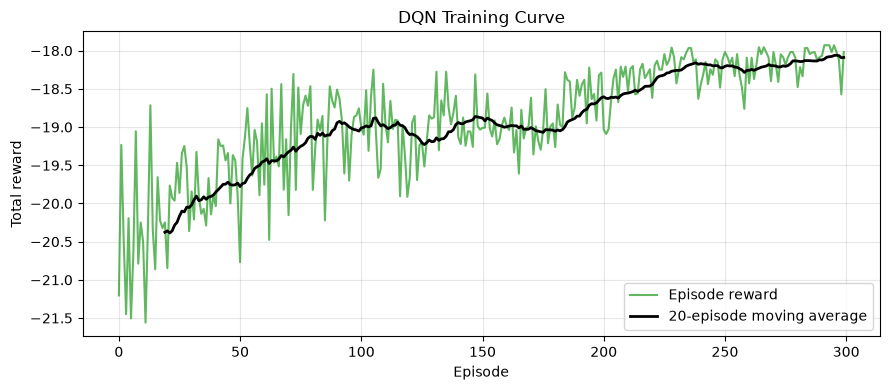

In [56]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(episode_rewards, color="tab:green", alpha=0.75, label="Episode reward")
if len(episode_rewards) >= 20:
    moving_avg = np.convolve(episode_rewards, np.ones(20) / 20, mode="valid")
    ax.plot(np.arange(19, len(episode_rewards)), moving_avg, color="black", linewidth=2, label="20-episode moving average")
ax.set_xlabel("Episode")
ax.set_ylabel("Total reward")
ax.set_title("DQN Training Curve")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Step 7. Test the Learned Policy

After training, we evaluate the learned policy for one full day and compare it with two simple baselines:

- **No battery**: the load is fully served by the grid;
- **Straightforward rule**: repeatedly charge until the battery reaches full SOC, then discharge until it reaches empty SOC, and repeat. This rule completely ignores electricity price and load shape.

This comparison helps students see what the DQN learned and whether it behaves sensibly. The reported cost is grid-energy cost only: it is computed from grid power, electricity price, and the one-hour time step. The DQN reward also includes small cycling, invalid-action, and terminal-SOC penalty terms, so reward and grid-energy cost are related but not identical. The straightforward rule is intentionally naive: it ignores price and load information, so it is a simple sanity-check baseline rather than a carefully designed controller.


In [57]:
def baseline_no_battery(load_kw, price_per_kwh, dt_hours=1.0):
    """Daily grid-energy cost with no battery for one-hour or user-specified time steps."""
    load_kw = np.asarray(load_kw, dtype=float)
    price_per_kwh = np.asarray(price_per_kwh, dtype=float)
    return float(np.sum(load_kw * price_per_kwh * dt_hours))


def rule_based_policy(state, env):
    # This baseline is intentionally blind: it uses only SOC, not price or load.
    """Straightforward baseline: cycle between full charge and full discharge."""
    soc_tol = 1e-9
    if not env.history:
        return 2  # start by charging
    if env.soc_kwh >= env.capacity_kwh - soc_tol:
        return 0  # switch to discharge at full SOC
    if env.soc_kwh <= soc_tol:
        return 2  # switch to charge at empty SOC

    previous_battery_power = env.history[-1]["battery_power_kw"]
    if previous_battery_power < 0:
        return 0  # keep discharging until empty
    return 2      # keep charging until full


def dqn_policy(state, env):
    """Greedy policy from the trained DQN."""
    with torch.no_grad():
        state_tensor = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        return int(policy_net(state_tensor).argmax(dim=1).item())


def run_policy(policy_fn, label):
    # Use the same evaluator for every policy so the reported costs are comparable.
    """Run a policy for one day and return summary statistics and history."""
    eval_env = BatteryStorageEnv(load_kw, price_per_kwh)
    state = eval_env.reset()
    done = False
    total_reward = 0.0
    terminal_penalty = 0.0

    while not done:
        action = policy_fn(state, eval_env)
        next_state, reward, done, info = eval_env.step(action)
        total_reward += reward
        terminal_penalty += info["terminal_penalty"]
        state = next_state

    energy_cost = sum(row["energy_cost"] for row in eval_env.history)
    return {
        "label": label,
        "history": eval_env.history,
        "energy_cost": float(energy_cost),
        "terminal_penalty": float(terminal_penalty),
        "total_reward": float(total_reward),
        "initial_soc_fraction": eval_env.initial_soc_kwh / eval_env.capacity_kwh,
    }


no_battery_cost = baseline_no_battery(load_kw, price_per_kwh)
rule_result = run_policy(rule_based_policy, "Straightforward rule")
dqn_result = run_policy(dqn_policy, "DQN")

print(f"No battery grid-energy cost: ${no_battery_cost:6.2f}")
print(f"Straightforward rule grid-energy cost: ${rule_result['energy_cost']:6.2f}  (terminal penalty: {rule_result['terminal_penalty']:.2f})")
print(f"DQN grid-energy cost:        ${dqn_result['energy_cost']:6.2f}  (terminal penalty: {dqn_result['terminal_penalty']:.2f})")
print()
print("DQN action schedule:")
print([row["action_name"] for row in dqn_result["history"]])


No battery grid-energy cost: $191.58
Straightforward rule grid-energy cost: $205.91  (terminal penalty: 8.84)
DQN grid-energy cost:        $178.37  (terminal penalty: 0.00)

DQN action schedule:
['idle', 'idle', 'charge', 'charge', 'charge', 'charge', 'discharge', 'discharge', 'idle', 'idle', 'charge', 'charge', 'idle', 'idle', 'idle', 'charge', 'charge', 'discharge', 'discharge', 'discharge', 'discharge', 'idle', 'idle', 'idle']


## Step 8. Visualize Results

The plots below compare the no-battery case, the straightforward SOC-cycling rule, and the learned DQN policy. The no-battery SOC and battery-power traces are shown as zero reference lines because no storage device is used in that baseline.


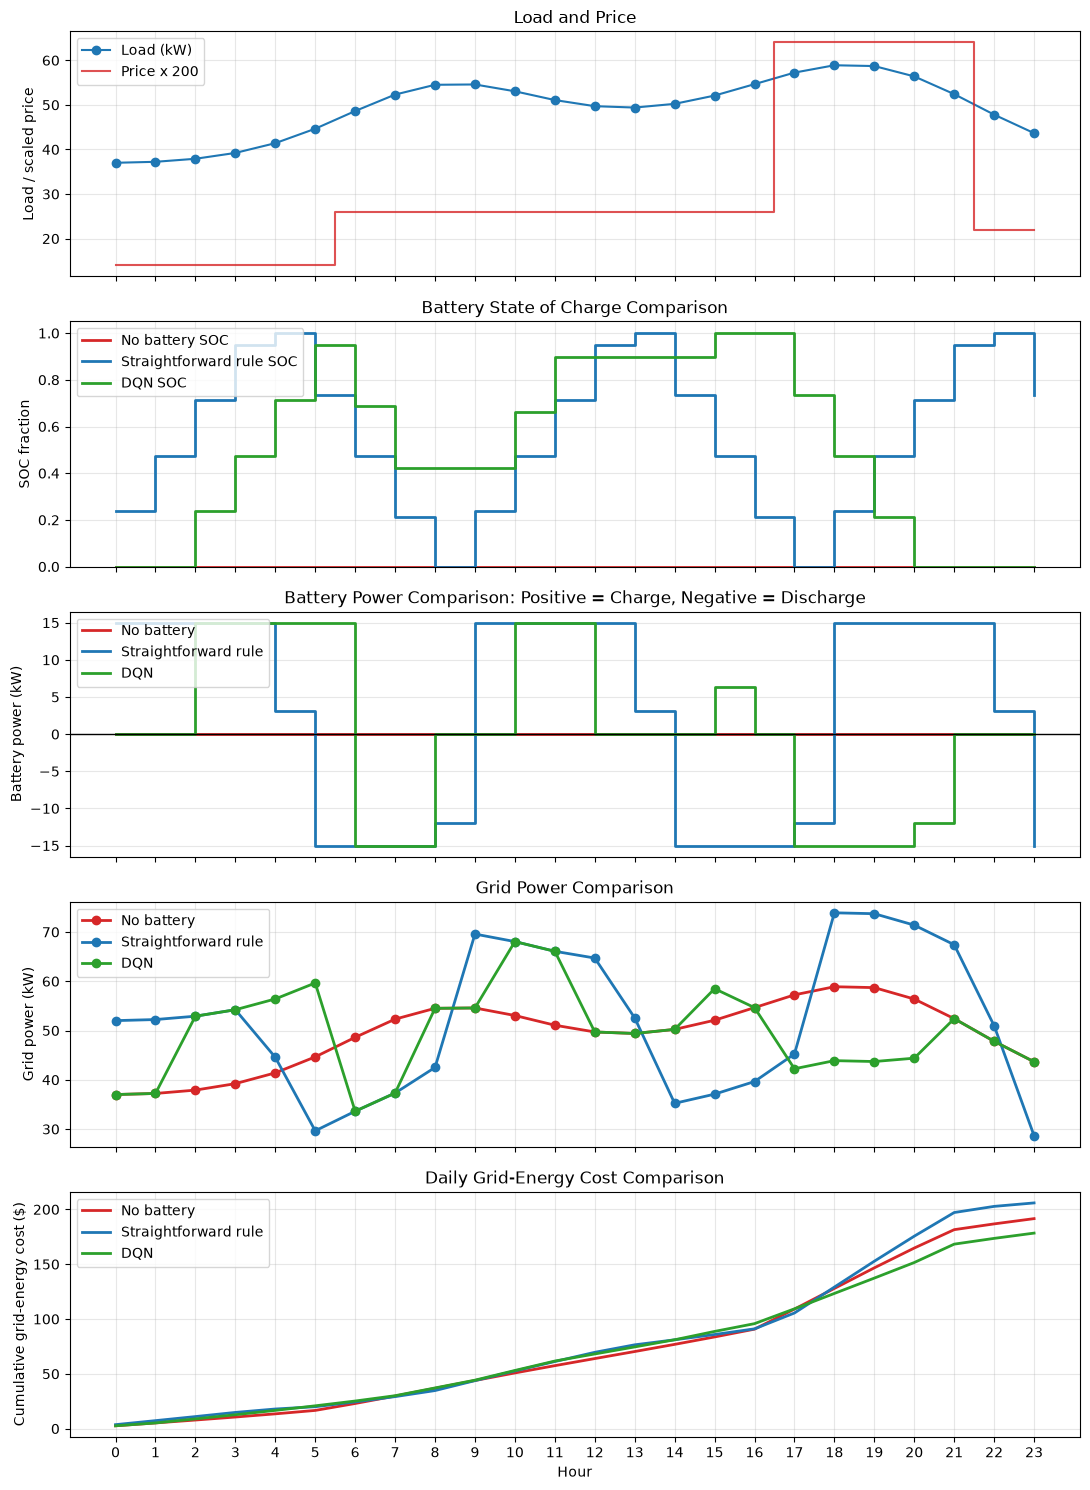

In [58]:
def history_values(result, key):
    return np.array([row[key] for row in result["history"]], dtype=float)


# Build aligned time-series arrays so the three policies can be compared on the same axes.
no_battery_soc = np.zeros_like(HOURS, dtype=float)
rule_soc = history_values(rule_result, "soc_fraction")
dqn_soc = history_values(dqn_result, "soc_fraction")

no_battery_power = np.zeros_like(HOURS, dtype=float)
rule_power = history_values(rule_result, "battery_power_kw")
dqn_power = history_values(dqn_result, "battery_power_kw")

no_battery_grid = load_kw.astype(float)
rule_grid = history_values(rule_result, "grid_power_kw")
dqn_grid = history_values(dqn_result, "grid_power_kw")

no_battery_cost_cumulative = np.cumsum(no_battery_grid * price_per_kwh * 1.0)
rule_cost_cumulative = np.cumsum(history_values(rule_result, "energy_cost"))
dqn_cost_cumulative = np.cumsum(history_values(dqn_result, "energy_cost"))

fig, axes = plt.subplots(5, 1, figsize=(11, 15), sharex=True)

axes[0].plot(HOURS, load_kw, marker="o", label="Load (kW)", color="tab:blue")
axes[0].step(HOURS, price_per_kwh * 200, where="mid", label="Price x 200", color="tab:red", alpha=0.8)
axes[0].set_ylabel("Load / scaled price")
axes[0].set_title("Load and Price")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

initial_soc_fraction_used = dqn_result["initial_soc_fraction"]
axes[1].step(HOURS, no_battery_soc, where="post", color="tab:red", linewidth=2, label="No battery SOC")
axes[1].step(HOURS, rule_soc, where="post", color="tab:blue", linewidth=2, label="Straightforward rule SOC")
axes[1].step(HOURS, dqn_soc, where="post", color="tab:green", linewidth=2, label="DQN SOC")
axes[1].set_ylabel("SOC fraction")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Battery State of Charge Comparison")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

axes[2].step(HOURS, no_battery_power, where="post", color="tab:red", linewidth=2, label="No battery")
axes[2].step(HOURS, rule_power, where="post", color="tab:blue", linewidth=2, label="Straightforward rule")
axes[2].step(HOURS, dqn_power, where="post", color="tab:green", linewidth=2, label="DQN")
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set_ylabel("Battery power (kW)")
axes[2].set_title("Battery Power Comparison: Positive = Charge, Negative = Discharge")
axes[2].legend(loc="upper left")
axes[2].grid(True, axis="y", alpha=0.3)

axes[3].plot(HOURS, no_battery_grid, marker="o", label="No battery", linewidth=2, color="tab:red")
axes[3].plot(HOURS, rule_grid, marker="o", label="Straightforward rule", linewidth=2, color="tab:blue")
axes[3].plot(HOURS, dqn_grid, marker="o", label="DQN", linewidth=2, color="tab:green")
axes[3].set_ylabel("Grid power (kW)")
axes[3].set_title("Grid Power Comparison")
axes[3].legend(loc="upper left")
axes[3].grid(True, alpha=0.3)

axes[4].plot(HOURS, no_battery_cost_cumulative, label="No battery", linewidth=2, color="tab:red")
axes[4].plot(HOURS, rule_cost_cumulative, label="Straightforward rule", linewidth=2, color="tab:blue")
axes[4].plot(HOURS, dqn_cost_cumulative, label="DQN", linewidth=2, color="tab:green")
axes[4].set_xlabel("Hour")
axes[4].set_ylabel("Cumulative grid-energy cost ($)")
axes[4].set_title("Daily Grid-Energy Cost Comparison")
axes[4].legend(loc="upper left")
axes[4].grid(True, alpha=0.3)
axes[4].set_xticks(HOURS)

fig.tight_layout()
plt.show()


## Further Reading

For a broader view of how model-free reinforcement learning can be connected with practical microgrid control problems, see:

B. She, F. Li, H. Cui, J. Zhang, and R. Bo, "Fusion of Microgrid Control With Model-Free Reinforcement Learning: Review and Vision," *IEEE Transactions on Smart Grid*, vol. 14, no. 4, pp. 3232-3245, Jul. 2023, doi: [10.1109/TSG.2022.3222323](https://doi.org/10.1109/TSG.2022.3222323).
